# CDS 303 – Final Project 2
## NYC Airbnb Listings: Data Integration and PCA

**Team Members:** Seohyun Hong, Sieun Woo, Seoyoung Yun

**Primary Dataset:** Inside Airbnb – New York City Listings (September 14, 2026)

**Source:** https://insideairbnb.com/get-the-data/

### Project Overview

Our project focuses on differences among Airbnb listings in New York City. In Project 1, we examined price, availability, and minimum-night requirements. For Project 2, we added seven supplementary datasets and applied PCA to find the main dimensions of variation. Our main audience is current and prospective Airbnb hosts in NYC.
We will perform clustering and classification in a later project stage.

### Input Files

Put the notebook and these eight CSV files in the same folder. The code uses relative paths, so no personal file paths are needed.

- `listings.csv`
- `calendar.csv`
- `CommonPlace_20261109.csv`
- `MTA_Subway_Stations_and_Complexes_20261117.csv`
- `nyc_airports.csv`
- `DOHMH_New_York_City_Restaurant_Inspection_Results_20261117.csv`
- `NYPD_Complaint_Data_Current_(Year_To_Date)_20261117.csv`
- `311_Service_Requests_from_2020_to_Present_20261117-2.csv`

## Step 1. Import Libraries

We imported NumPy and Pandas to prepare the data, and Matplotlib and Seaborn to make graphs. We used Scikit-learn for location matching, standardization, and PCA. Our PCA code follows the professor's Demo 06.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings(action = 'ignore')

from pathlib import Path

Path('data').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

from sklearn.neighbors import BallTree

## Step 2. Load the Airbnb Dataset

We loaded the NYC Airbnb Listings dataset. It contains 29,918 listings and 90 variables. Each row represents one listing, and `id` identifies a listing. We only loaded one copy of the listings file.

In [2]:
df = pd.read_csv('listings.csv', low_memory = False)
print('Rows and columns:', df.shape)
print('Unique listing IDs:', df['id'].is_unique)
df.head()

Rows and columns: (29918, 90)
Unique listing IDs: True


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1352055619826961511,https://www.airbnb.com/rooms/1352055619826961511,20260914002229,2026-09-14,NaN,"New 3 bed, 1.5 bath",This stylish place to stay is perfect for grou...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,677651543,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,1215930899551057941,https://www.airbnb.com/rooms/1215930899551057941,20260914002229,2026-09-14,NaN,Queens apartament,Bring the whole family to this great place wit...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,392517036,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1203866180302079266,https://www.airbnb.com/rooms/1203866180302079266,20260914002229,2026-09-15,NaN,Luxury Meets Comfort Stay NYC,This stylish place is close to must-see destin...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,115082911,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,15310580,https://www.airbnb.com/rooms/15310580,20260914002229,2026-09-15,previous scrape,Nice apartment in Gramercy.,Nice apartment in one of the best neighbors of NY,NaN,https://a0.muscache.com/pictures/c2c78aad-78c9...,27336207,...,4.88,5.00,4.25,NaN,NaN,2,2,0,0,0.07
4,32842295,https://www.airbnb.com/rooms/32842295,20260914002229,2026-09-15,previous scrape,Beautiful bedroom and full bathroom,NaN,NaN,https://a0.muscache.com/pictures/b946d6e3-07d6...,233227636,...,4.89,4.78,4.75,NaN,NaN,1,0,1,0,0.40


## Step 3. Check the Project 1 Variables

We checked price, availability, and minimum-night requirements from Project 1. We also kept room type, borough, host listing count, and license information for later comparisons. Categorical variables are not used directly as PCA inputs.


In [3]:
clustering_vars = ['price', 'availability_30', 'availability_365', 'minimum_nights']
classification_vars = ['room_type', 'neighbourhood_group_cleansed',
                       'calculated_host_listings_count', 'license']
print(df[clustering_vars + classification_vars].dtypes)
df[clustering_vars + classification_vars].head()

price                                 str
availability_30                     int64
availability_365                    int64
minimum_nights                    float64
room_type                             str
neighbourhood_group_cleansed          str
calculated_host_listings_count      int64
license                               str
dtype: object


,price,availability_30,availability_365,minimum_nights,room_type,neighbourhood_group_cleansed,calculated_host_listings_count,license
0,NaN,30,365,30.0,Entire home/apt,Brooklyn,1,NaN
1,$164.55,29,364,31.0,Private room,Queens,1,NaN
2,NaN,30,269,30.0,Private room,Brooklyn,2,NaN
3,NaN,0,0,30.0,Entire home/apt,Manhattan,2,NaN
4,NaN,0,0,80.0,Private room,Brooklyn,1,NaN


## Step 4. Convert Price to a Number

The original price values contain dollar signs and commas. We converted price into a numerical variable called `price_num`. We did not replace missing prices with zero.


In [4]:
df['price_num'] = pd.to_numeric(
    df['price'].astype('string').str.replace(r'[\$,]', '', regex = True),
    errors = 'coerce'
)
df[['price', 'price_num']].head(10)

,price,price_num
0,NaN,<NA>
1,$164.55,164.55
2,NaN,<NA>
3,NaN,<NA>
4,NaN,<NA>
5,NaN,<NA>
6,NaN,<NA>
7,$236.00,236.0
8,$143.47,143.47
9,$102.97,102.97


## Step 5. Check Missing Values

We found 10,512 missing prices, or about 35.1% of the listings. We also compared availability for listings with and without reported prices. The missing-price group generally has lower availability. We use positive reported prices for our main PCA, but this sample may not represent all NYC listings.


In [5]:
basic_cols = ['price_num', 'availability_30', 'availability_365', 'minimum_nights']
missing = pd.DataFrame({
    'Missing Count': df[basic_cols].isna().sum(),
    'Missing %': (df[basic_cols].isna().mean() * 100).round(1)
})
print(missing)
print(pd.crosstab(df['availability_365'] == 0, df['price_num'].isna()))

df['has_price'] = df['price_num'].notna() & (df['price_num'] > 0)
price_comparison = df.groupby('has_price')[
    ['availability_30', 'availability_365', 'minimum_nights']
].median()
print('\nPrice availability comparison:')
print(price_comparison)

                  Missing Count  Missing %
price_num                 10512       35.1
availability_30               0        0.0
availability_365              0        0.0
minimum_nights                8        0.0
price_num         False  True 
availability_365              
False             19397   3503
True                  9   7009

Price availability comparison:
           availability_30  availability_365  minimum_nights
has_price                                                   
False                  0.0               0.0            30.0
True                  10.0             276.0            30.0


## Step 6. Summary Statistics and Graphs

We checked the distributions of price, availability, and minimum nights. We also used histograms to look for unusual values. Some listings had very high prices, so we reduced the effect of extreme values before PCA.


       price_num  availability_30  availability_365  minimum_nights
count    19406.0          29918.0           29918.0         29910.0
mean       310.2              9.4             188.8            26.8
std        574.1             11.7             140.5            28.5
min         17.7              0.0               0.0             1.0
25%        103.7              0.0              14.0            30.0
50%        182.4              2.0             227.0            30.0
75%        337.0             19.0             323.0            30.0
max      31537.8             30.0             365.0          1124.0
99th percentile price: 2000.0


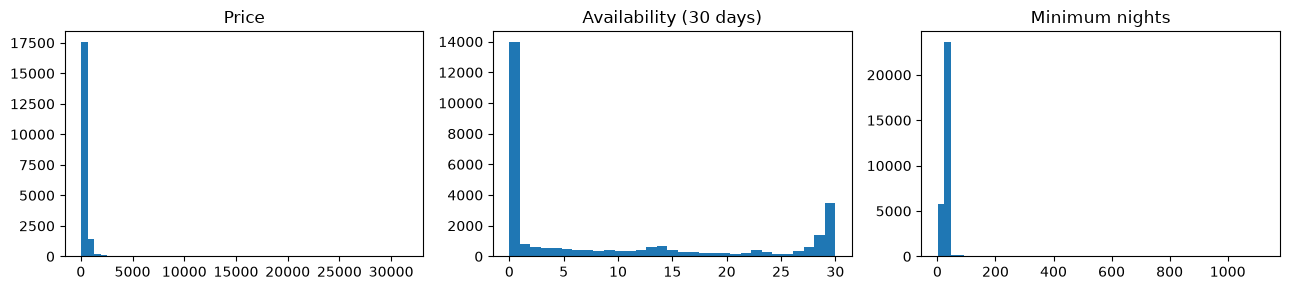

In [6]:
print(df[basic_cols].describe().round(1))
print('99th percentile price:', df['price_num'].quantile(.99))

fig, axes = plt.subplots(1, 3, figsize = (13, 3))
axes[0].hist(df['price_num'].dropna(), bins = 50)
axes[0].set_title('Price')
axes[1].hist(df['availability_30'], bins = 31)
axes[1].set_title('Availability (30 days)')
axes[2].hist(df['minimum_nights'].dropna(), bins = 50)
axes[2].set_title('Minimum nights')
plt.tight_layout()
plt.savefig('figures/airbnb_distributions.png', dpi = 150)
plt.show()

## Step 7. Prepare One Row per Listing

We kept the listing ID, coordinates, and useful listing variables. We removed invalid coordinates before matching outside datasets. Each row still represents one Airbnb listing.


In [7]:
cols = ['id', 'latitude', 'longitude', 'price_num', 'availability_30',
        'availability_365', 'minimum_nights', 'room_type',
        'neighbourhood_group_cleansed', 'calculated_host_listings_count', 'license']
combined = df[cols].copy()
combined = combined.rename(columns={'latitude':'Latitude', 'longitude':'Longitude'})
combined = combined[
    combined['Latitude'].between(40.3, 41.1) &
    combined['Longitude'].between(-74.4, -73.4)
].copy()
print('Listings after coordinate check:', combined.shape)
print('Unique listing IDs:',combined['id'].is_unique)

Listings after coordinate check: (29918, 11)
Unique listing IDs: True


## Step 8. Summarize and Merge Calendar Data

The Calendar dataset has many dates for each listing. We summarized weekday and weekend availability by listing ID before merging. This prevents duplicate listing rows. An unavailable date may be booked or blocked, so it does not confirm occupancy.


In [8]:
calendar_parts = []
for chunk in pd.read_csv('calendar.csv',
                         usecols=['listing_id', 'date', 'available'],
                         chunksize=500000):
    chunk['weekend'] = pd.to_datetime(chunk['date']).dt.dayofweek >= 5
    chunk['open'] = (chunk['available'] == 't').astype(int)
    part = chunk.groupby(['listing_id', 'weekend'])['open'].agg(['sum', 'count'])
    calendar_parts.append(part)

calendar_sum = pd.concat(calendar_parts).groupby(level=[0,1]).sum().reset_index()
print('Number of listing/weekend groups:', len(calendar_sum))
calendar_sum.head()

Number of listing/weekend groups: 59836


,listing_id,weekend,sum,count
0,2539,False,226,261
1,2539,True,92,104
2,6848,False,202,261
3,6848,True,82,104
4,6872,False,247,261


In [9]:
calendar_wide = calendar_sum.pivot(index='listing_id', columns='weekend',
                                    values=['sum', 'count']).fillna(0)
calendar_wide.columns = ['_'.join([a, 'weekend' if b else 'weekday'])
                         for a, b in calendar_wide.columns]
calendar_wide = calendar_wide.reset_index()
calendar_wide['weekday_availability_rate'] = (
    calendar_wide['sum_weekday'] / calendar_wide['count_weekday'])
calendar_wide['weekend_availability_rate'] = (
    calendar_wide['sum_weekend'] / calendar_wide['count_weekend'])

calendar_summary = calendar_wide[['listing_id', 'weekday_availability_rate',
                                  'weekend_availability_rate']]
print('Unique calendar listing IDs:',calendar_summary['listing_id'].is_unique)
combined = combined.merge(calendar_summary, left_on='id', right_on='listing_id',
                          how='left', validate='one_to_one')
print('Rows after calendar merge:',len(combined))

Unique calendar listing IDs: True
Rows after calendar merge: 29918


## Step 9. Match Locations by Distance

Other NYC datasets do not have Airbnb listing IDs. We used latitude and longitude to find nearby locations. The distance calculations let us count nearby facilities and find the nearest subway station or airport.


In [10]:
listing_points = np.radians(combined[['Latitude','Longitude']].to_numpy())
earth_radius = 6371000

def clean_locations(data):
    data = data.copy()
    data['Latitude'] = pd.to_numeric(data['Latitude'], errors='coerce')
    data['Longitude'] = pd.to_numeric(data['Longitude'], errors='coerce')
    return data[data['Latitude'].between(40.3,41.1) &
                data['Longitude'].between(-74.4,-73.4)].copy()

def count_nearby(data, radius):
    tree = BallTree(np.radians(data[['Latitude','Longitude']]), metric='haversine')
    return tree.query_radius(listing_points, r=radius/earth_radius, count_only=True)

def nearest_km(data):
    tree = BallTree(np.radians(data[['Latitude','Longitude']]), metric='haversine')
    distance, index = tree.query(listing_points, k=1)
    return distance[:,0]*earth_radius/1000

## Step 10. Add Parks and Museums

We used NYC CommonPlace data to find parks and museums. We counted each type of facility within 1 kilometer of every Airbnb listing. These variables describe nearby recreational and cultural facilities.


In [11]:
common = pd.read_csv('CommonPlace_20261109.csv',
                     usecols=['PLACEID','the_geom','FACILITY TYPE','FACILITY DOMAINS'])
common = common.drop_duplicates('PLACEID')
points = common['the_geom'].str.extract(r'POINT\s*\(\s*([-\d.]+)\s+([-\d.]+)\s*\)')
common['Longitude'] = pd.to_numeric(points[0],errors='coerce')
common['Latitude'] = pd.to_numeric(points[1],errors='coerce')
common = clean_locations(common)

parks = common[(common['FACILITY TYPE']==4) & (common['FACILITY DOMAINS']==1)]
museums = common[(common['FACILITY TYPE']==3) & (common['FACILITY DOMAINS']==4)]
combined['parks_1km'] = count_nearby(parks, 1000)
combined['museums_1km'] = count_nearby(museums, 1000)
print('Parks:',len(parks),'Museums:',len(museums))

Parks: 1274 Museums: 95


## Step 11. Add Subway Access

We used the MTA dataset and kept one record per subway station complex. We calculated the distance in kilometers from each listing to the nearest station complex. This gives us a measure of subway access.


In [12]:
subway = pd.read_csv('MTA_Subway_Stations_and_Complexes_20261117.csv',
                     usecols=['Complex ID','Latitude','Longitude'])
subway = subway.drop_duplicates('Complex ID')
subway = clean_locations(subway)
combined['subway_distance_km'] = nearest_km(subway)
print('Subway complexes:',len(subway))

Subway complexes: 445


## Step 12. Add Airport Access

We used JFK, LGA, and EWR airports because they serve the NYC area. We calculated the distance from each listing to the nearest airport. This adds information about travel access.


In [13]:
airports = pd.read_csv('nyc_airports.csv')
airports = airports[airports['iata_code'].isin(['JFK','LGA','EWR'])]
airports = airports.rename(columns={'latitude_deg':'Latitude',
                                    'longitude_deg':'Longitude'})
airports = clean_locations(airports)
combined['airport_distance_km'] = nearest_km(airports)
print(airports[['iata_code','name']])

  iata_code                                   name
0       EWR   Newark Liberty International Airport
1       JFK  John F. Kennedy International Airport
2       LGA                      LaGuardia Airport


## Step 13. Add Restaurant Information

We used restaurant inspection records to count nearby restaurants. We kept one record per restaurant using `CAMIS`. To reduce the time difference with Airbnb data, we only used inspection dates on or before September 14, 2026. An earlier inspection does not prove that a restaurant was still open on that date.


In [14]:
rest = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20261117.csv',
                   usecols=['CAMIS','INSPECTION DATE','Latitude','Longitude'],
                   low_memory=False)
print('Original inspection rows:',len(rest))
rest['INSPECTION DATE'] = pd.to_datetime(rest['INSPECTION DATE'],errors='coerce')

rest = rest[rest['INSPECTION DATE'] <= '2026-09-14'].copy()
rest = rest.sort_values('INSPECTION DATE').drop_duplicates('CAMIS',keep='last')
rest = clean_locations(rest)
combined['restaurants_500m'] = count_nearby(rest, 500)
print('Restaurants with earlier inspection records:',len(rest))

Original inspection rows: 295040
Restaurants with earlier inspection records: 30161


## Step 14. Add NYPD Reported Incidents

We selected NYPD incidents from January through August 2026 and removed duplicate complaint IDs. We counted incidents within 1 kilometer of each listing. This is a count of reported incidents, not a direct measure of neighborhood safety.


In [15]:
crime = pd.read_csv('NYPD_Complaint_Data_Current_(Year_To_Date)_20261117.csv',
                    usecols=['CMPLNT_NUM','CMPLNT_FR_DT','Latitude','Longitude'],
                    low_memory=False)
crime = crime.drop_duplicates('CMPLNT_NUM')
crime['date'] = pd.to_datetime(crime['CMPLNT_FR_DT'],errors='coerce')
crime = crime[(crime['date'] >= '2026-01-01') &
              (crime['date'] < '2026-09-01')]
crime = clean_locations(crime)
combined['reported_incidents_1km'] = count_nearby(crime, 1000)
print('Jan–Aug 2026 reported incidents:',len(crime))

Jan–Aug 2026 reported incidents: 372940


## Step 15. Add NYC 311 Residential Noise Complaints

The 311 file was downloaded from NYC Open Data with two filters: Problem (formerly Complaint Type) = Noise - Residential and Created Date = September 14, 2025 – September 14, 2026. To keep the file small, we exported only five columns (`Unique Key`, `Created Date`, `Borough`, `Latitude`, `Longitude`). The complaint-type column is not in the file, but every row is a residential noise complaint.

We selected complaints from January through August 2026 to match the NYPD time window, removed duplicate keys, and counted complaints within 1 kilometer of each listing. In the code, this variable is named `service_requests_1km`, but it counts residential noise complaints. A complaint is a report, not a measured noise level.


In [16]:
requests = pd.read_csv('311_Service_Requests_from_2020_to_Present_20261117-2.csv',low_memory=False)
print('311 columns:',requests.columns.tolist())
requests = requests.drop_duplicates('Unique Key')
requests['date'] = pd.to_datetime(requests['Created Date'],
    format='%m/%d/%Y %I:%M:%S %p',errors='coerce')
requests = requests[(requests['date'] >= '2026-01-01') &
                    (requests['date'] < '2026-09-01')]
requests = clean_locations(requests)
combined['service_requests_1km'] = count_nearby(requests, 1000)
print('Jan–Aug 2026 requests in supplied extract:',len(requests))

311 columns: ['Unique Key', 'Created Date', 'Borough', 'Latitude', 'Longitude']
Jan–Aug 2026 requests in supplied extract: 249908


## Step 16. Count Nearby Airbnb Listings

We counted other Airbnb listings within 500 meters and excluded each listing itself. This measures nearby Airbnb supply, not actual bookings or demand.


In [17]:
airbnb_tree = BallTree(listing_points,metric='haversine')
combined['nearby_airbnb_listings_500m'] = (
    airbnb_tree.query_radius(listing_points,r=500/earth_radius,count_only=True)-1)
print(combined['nearby_airbnb_listings_500m'].describe().round(1))

count    29918.0
mean       209.8
std        184.2
min          0.0
25%         61.0
50%        172.0
75%        292.0
max        882.0
Name: nearby_airbnb_listings_500m, dtype: float64


## Step 17. Check the Combined Data

We combined the primary Airbnb data with seven supplementary datasets. Calendar records were summarized by `listing_id` before merging with `id`. Other datasets were connected by geographic distance. After merging, we still had 29,918 listings and no duplicate listing IDs. Each row represents one listing.

Some datasets were downloaded after the September Airbnb snapshot. We keep those variables for additional context, but do not treat them as exact September conditions.


In [18]:
print('Original Airbnb rows:',len(df))
print('Combined rows:',len(combined))
print('Duplicate listing IDs:',combined['id'].duplicated().sum())
print('Number of variables:',len(combined.columns))

assert combined['id'].is_unique
assert len(combined) == len(df)
combined.to_csv('data/airbnb_integrated_part1.csv',index=False)
print('Saved: data/airbnb_integrated_part1.csv')

summary = pd.DataFrame({'Variable':combined.columns,
                        'Missing Count':combined.isna().sum().values,
                        'Missing %':(combined.isna().mean().values*100).round(1)})
summary.to_csv('data/integrated_missing_summary.csv',index=False)
print(summary.to_string(index=False))

Original Airbnb rows: 29918
Combined rows: 29918
Duplicate listing IDs: 0
Number of variables: 22
Saved: data/airbnb_integrated_part1.csv
                      Variable  Missing Count  Missing %
                            id              0        0.0
                      Latitude              0        0.0
                     Longitude              0        0.0
                     price_num          10512       35.1
               availability_30              0        0.0
              availability_365              0        0.0
                minimum_nights              8        0.0
                     room_type              0        0.0
  neighbourhood_group_cleansed              0        0.0
calculated_host_listings_count              0        0.0
                       license          24791       82.9
                    listing_id              0        0.0
     weekday_availability_rate              0        0.0
     weekend_availability_rate              0        0.0
       

## Step 18. Research Question and Audience

**Research Question:** What are the main patterns of variation among NYC Airbnb listings based on price, availability, minimum-night requirements, nearby Airbnb supply, and reported neighborhood incidents?

**Audience:** Current and prospective Airbnb hosts and small property managers in NYC.

**Relevance:** Hosts may want to know how their listings compare with other properties. Price alone does not describe all listing differences.

**Potential Use:** PCA can show the main dimensions of variation. Other supplementary variables can help us compare neighborhood conditions. These results do not directly predict bookings, revenue, or profitability.


## Step 19. Select Variables for PCA

We used listings with positive reported prices because price is one of our main variables. We selected six numerical variables: log price, availability over 30 days, availability over 365 days, log minimum nights, log nearby Airbnb supply, and log NYPD reported incidents.

We used log transformations for highly skewed variables and the median for a few missing numerical values. We excluded IDs, coordinates, and categorical variables from PCA. The remaining environmental variables are used only for additional comparisons.


In [19]:
priced = combined[combined['price_num'].notna() &
                  (combined['price_num'] > 0)].copy()

print('All listings:',len(combined))
print('Listings with reported prices:',len(priced))
print('Excluded listings:',len(combined)-len(priced))

priced['log_price'] = np.log1p(
    priced['price_num'].clip(upper=priced['price_num'].quantile(.99)))
priced['log_minimum_nights'] = np.log1p(
    priced['minimum_nights'].clip(upper=priced['minimum_nights'].quantile(.99)))
priced['log_nearby_airbnb_listings_500m'] = np.log1p(
    priced['nearby_airbnb_listings_500m'])
priced['log_reported_incidents_1km'] = np.log1p(
    priced['reported_incidents_1km'])

All listings: 29918
Listings with reported prices: 19406
Excluded listings: 10512


In [20]:
pca_vars = ['log_price', 'availability_30', 'availability_365',
            'log_minimum_nights', 'log_nearby_airbnb_listings_500m',
            'log_reported_incidents_1km']

airbnb_pca = priced[pca_vars].copy()
print('Missing values before imputation:')
print(airbnb_pca.isna().sum())
airbnb_pca = airbnb_pca.fillna(airbnb_pca.median())
print('PCA table:', airbnb_pca.shape)
assert not airbnb_pca.isna().any().any()
airbnb_pca.to_csv('data/airbnb_pca_input.csv',index=False)

Missing values before imputation:
log_price                          0
availability_30                    0
availability_365                   0
log_minimum_nights                 7
log_nearby_airbnb_listings_500m    0
log_reported_incidents_1km         0
dtype: int64
PCA table: (19406, 6)


## Step 20. Standardize Variables

The variables have different units, including days, distances, and counts. We used `StandardScaler` to put the PCA variables on the same scale. This follows the professor's Demo 06.


In [21]:
from sklearn.preprocessing import StandardScaler

airbnb_st = StandardScaler().fit_transform(airbnb_pca)
airbnb_st = pd.DataFrame(airbnb_st, columns = airbnb_pca.columns)
airbnb_st.head(10)

,log_price,availability_30,availability_365,log_minimum_nights,log_nearby_airbnb_listings_500m,log_reported_incidents_1km
0,-0.199096,1.363303,1.079222,0.605684,-1.999291,-2.019203
1,0.224853,1.447230,1.088989,0.578106,-0.750886,-0.062666
2,-0.360034,1.447230,1.040151,0.578106,-2.099820,-2.231521
3,-0.748750,1.363303,-0.727790,0.578106,-1.577981,-1.065133
4,-0.408195,1.363303,-0.727790,0.578106,-1.388778,-1.059416
5,-0.290012,1.447230,0.161065,0.578106,-1.431810,-1.060367
6,-0.914401,1.447230,1.088989,0.578106,-1.477452,0.798115
7,-0.429948,1.447230,1.088989,0.578106,-1.272725,-2.259277
8,-0.678272,1.363303,1.079222,0.578106,-1.388778,0.360313
9,-0.672718,1.363303,-0.864536,0.578106,-0.410607,0.086410


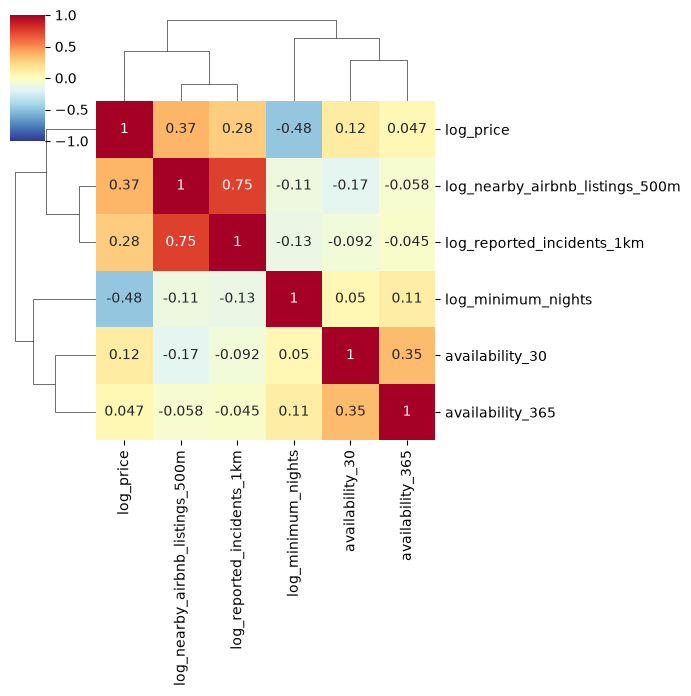

In [22]:
cor = airbnb_st.corr()
sns.clustermap(cor, annot = True, cmap = 'RdYlBu_r',
               vmin = -1, vmax = 1, figsize = (7,7))
plt.savefig('figures/correlation_clustermap.png',dpi=150,bbox_inches='tight')
plt.show()

## Step 21. Apply PCA

We applied PCA to the standardized data using the same method as Demo 06. We calculated all components first, then checked how much variance each component explained.


In [23]:
from sklearn.decomposition import PCA

pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(airbnb_st)

print('Eigenvalues:',pca.explained_variance_)
print('Explained variance ratio:',pca.explained_variance_ratio_)

Eigenvalues: [2.11865778 1.39558245 1.16125656 0.63736428 0.4601135  0.22733463]
Explained variance ratio: [0.35309143 0.23258509 0.19353279 0.10622191 0.07668163 0.03788715]


## Step 22. Explained Variance and Component Selection

We reported the explained variance ratio for every component. We also created a scree plot and a cumulative explained variance plot. We compared the eigenvalue-greater-than-one rule with the 80% cumulative variance rule.

For the revised six-variable PCA, the 80% rule selects four components. These components explain about 88.54% of the total variance. We use four components in our main interpretation.

In [24]:
exp_variance_ratio = pca.explained_variance_ratio_
variance_table = pd.DataFrame({
    'PC':['PC'+str(i) for i in range(1,len(exp_variance_ratio)+1)],
    'Explained Variance Ratio':exp_variance_ratio,
    'Cumulative Variance':np.cumsum(exp_variance_ratio)
})
print(variance_table.round(4).to_string(index=False))
variance_table.to_csv('data/pca_explained_variance.csv',index=False)

 PC  Explained Variance Ratio  Cumulative Variance
PC1                    0.3531               0.3531
PC2                    0.2326               0.5857
PC3                    0.1935               0.7792
PC4                    0.1062               0.8854
PC5                    0.0767               0.9621
PC6                    0.0379               1.0000


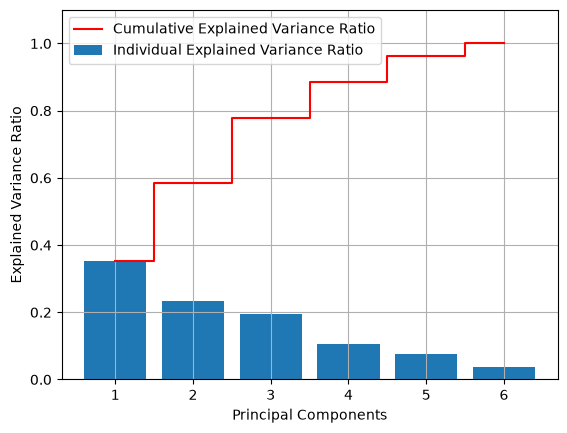

In [25]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1,len(exp_variance_ratio)+1)
    plt.bar(x_axis,exp_variance_ratio,align='center',
            label='Individual Explained Variance Ratio')
    plt.step(x_axis,np.cumsum(exp_variance_ratio),where='mid',
             color='red',label='Cumulative Explained Variance Ratio')
    plt.ylim(0,1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.legend()
    plt.grid()
    plt.savefig('figures/explained_variance_combined.png',dpi=150,bbox_inches='tight')
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

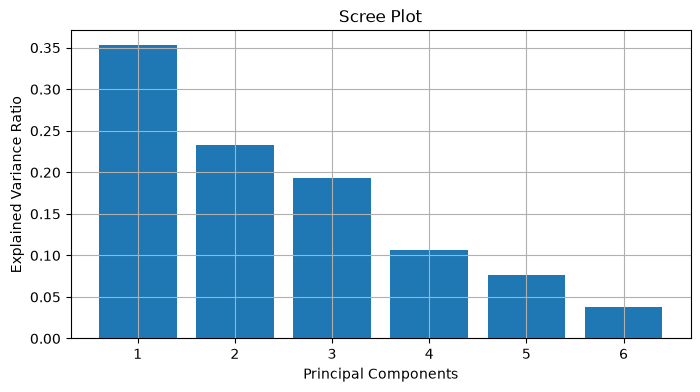

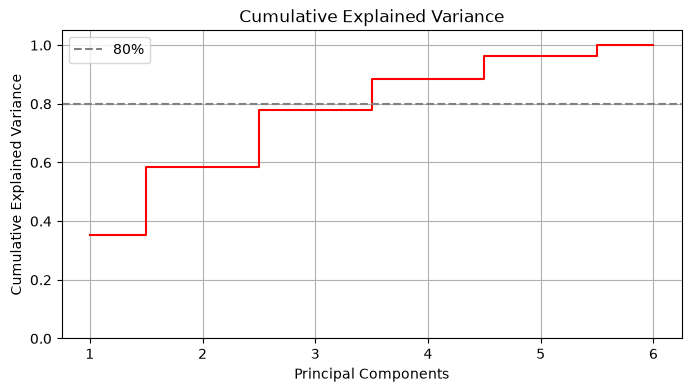

80% cumulative variance method: 4
Eigenvalue > 1 method: 3
Cumulative variance selected: 88.54 %


In [26]:
x_axis = range(1,len(exp_variance_ratio)+1)

# Scree plot
plt.figure(figsize=(8,4))
plt.bar(x_axis,exp_variance_ratio)
plt.xticks(x_axis)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid()
plt.savefig('figures/scree_plot.png',dpi=150,bbox_inches='tight')
plt.show()

# Cumulative explained variance plot
plt.figure(figsize=(8,4))
plt.step(x_axis,np.cumsum(exp_variance_ratio),where='mid',color='red')
plt.axhline(.80,color='gray',linestyle='--',label='80%')
plt.xticks(x_axis)
plt.ylim(0,1.05)
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid()
plt.savefig('figures/cumulative_explained_variance.png',dpi=150,bbox_inches='tight')
plt.show()

# Compare component selection rules
retained_80 = int(np.searchsorted(np.cumsum(exp_variance_ratio), .80) + 1)
retained_eigen = sum(pca.explained_variance_ > 1)
print('80% cumulative variance method:',retained_80)
print('Eigenvalue > 1 method:',retained_eigen)
print('Cumulative variance selected:',
      round(np.cumsum(exp_variance_ratio)[retained_80 - 1]*100,2),'%')
retained = retained_80

## Step 23. Interpret Component Loadings

We used the loading table to see which variables contributed most to each PC. We focused on the largest absolute loading values.

- **PC1 – Price and Local Activity:** Nearby Airbnb listings, reported incidents, and price have strong contributions.
- **PC2 – Listing Availability:** Availability over 30 and 365 days has strong contributions.
- **PC3 – Minimum Stay Requirements:** Minimum nights has the strongest contribution.
- **PC4 – Short-Term vs. Annual Availability:** The two availability measures contribute in opposite directions.

The signs show directions, not better or worse outcomes.


In [27]:
loadings = pca.components_
num_pc = pca.components_.shape[1]
pc_list = ['PC'+str(i) for i in list(range(1,num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list,loadings)))
loadings_df['variable'] = airbnb_pca.columns.values
loadings_df = loadings_df.set_index('variable')

print(loadings_df.round(3).to_string())
loadings_df.to_csv('data/pca_loadings.csv')

                                   PC1    PC2    PC3    PC4    PC5    PC6
variable                                                                 
log_price                        0.457  0.370 -0.337 -0.021  0.695 -0.241
availability_30                 -0.134  0.675  0.096 -0.678 -0.199  0.134
availability_365                -0.108  0.614  0.341  0.701 -0.071 -0.006
log_minimum_nights              -0.336 -0.155  0.685 -0.192  0.576 -0.159
log_nearby_airbnb_listings_500m  0.582 -0.069  0.365 -0.013  0.080  0.719
log_reported_incidents_1km       0.557 -0.044  0.398 -0.111 -0.368 -0.618


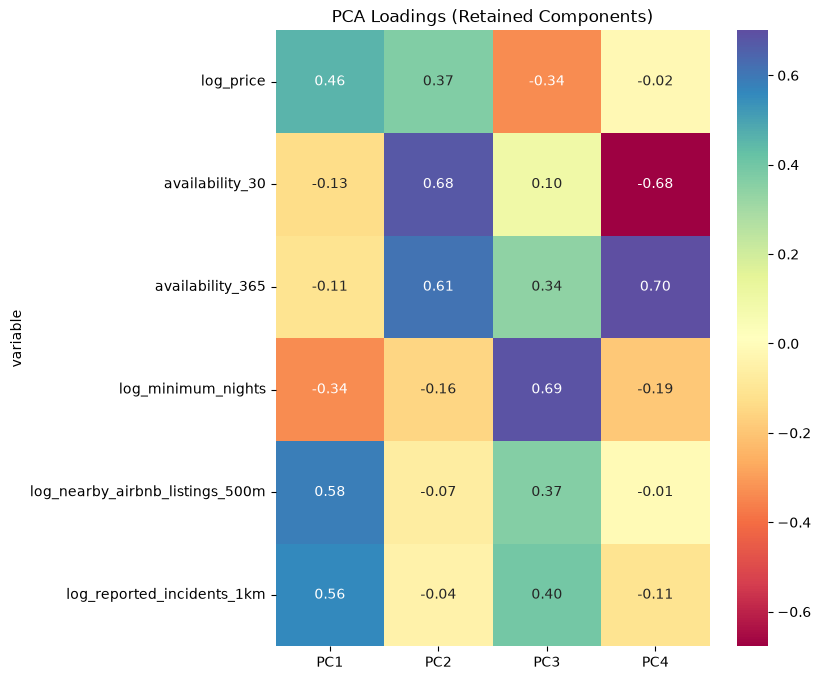

PC1 strongest loadings:
variable
log_nearby_airbnb_listings_500m    0.582160
log_reported_incidents_1km         0.556753
log_price                          0.456560
log_minimum_nights                 0.336301
Name: PC1, dtype: float64
PC2 strongest loadings:
variable
availability_30       0.675393
availability_365      0.613547
log_price             0.369729
log_minimum_nights    0.155153
Name: PC2, dtype: float64
PC3 strongest loadings:
variable
log_minimum_nights                 0.685158
log_reported_incidents_1km         0.397710
log_nearby_airbnb_listings_500m    0.365299
availability_365                   0.340626
Name: PC3, dtype: float64
PC4 strongest loadings:
variable
availability_365              0.700526
availability_30               0.677722
log_minimum_nights            0.192262
log_reported_incidents_1km    0.111257
Name: PC4, dtype: float64


In [28]:
plt.figure(figsize=(max(7,retained*1.3),8))
ax = sns.heatmap(loadings_df.iloc[:,:retained],annot=True,
                 fmt='.2f',cmap='Spectral')
plt.title('PCA Loadings (Retained Components)')
plt.savefig('figures/pca_loadings_heatmap.png',dpi=150,bbox_inches='tight')
plt.show()

for pc in pc_list[:retained]:
    print(pc,'strongest loadings:')
    print(loadings_df[pc].abs().sort_values(ascending=False).head(4))

## Step 24. PCA Scores and Biplot

We calculated PCA scores for each listing. We created a biplot with PC1 and PC2, which together explain about 58.57% of the total variance. We plotted a random sample of 3,000 listings to make the graph easier to read.

The points represent listings and the arrows represent the input variables. We also checked how the scores relate to other neighborhood variables. These relationships are descriptive and do not prove causation. The biplot does not confirm clusters.


In [29]:
scores = pca.transform(airbnb_st).transpose()
num_pc = pca.components_.shape[1]
pc_list = ['PC'+str(i) for i in list(range(1,num_pc+1))]
scores_df = pd.DataFrame.from_dict(dict(zip(pc_list,scores)))
scores_df.insert(0,'listing_id',priced['id'].to_numpy())
scores_df.to_csv('data/pca_scores.csv',index=False)
print(scores_df.head())

            listing_id       PC1       PC2       PC3       PC4       PC5  \
0  1215930899551057941 -2.881674  1.640893 -0.553428 -0.028626  0.443790   
1   791539646807027059 -0.875030  1.693420  0.530180 -0.316681  0.086190   
2   984905638210475309 -3.129586  1.634552 -0.644490 -0.079250  0.372136   
3             42220146 -2.151149  0.262687 -0.469074 -1.389584 -0.142532   
4             42220001 -1.882336  0.375335 -0.512566 -1.399849  0.107123   

        PC6  
0 -0.059387  
1 -0.459066  
2  0.054309  
3 -0.199763  
4 -0.149433  


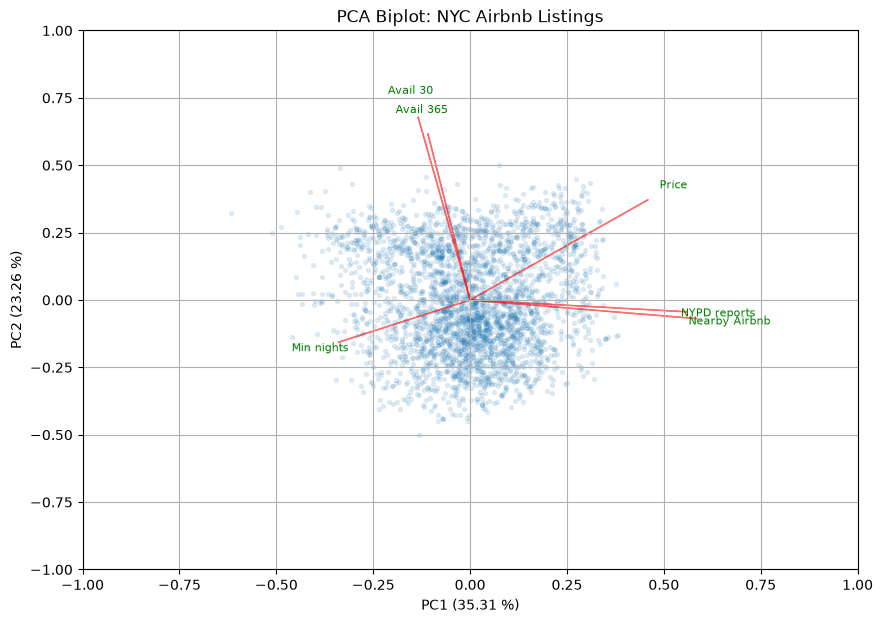

                            PC1   PC2
parks_1km                  0.31 -0.01
museums_1km                0.63  0.09
subway_distance_km        -0.48  0.10
airport_distance_km        0.16 -0.03
restaurants_500m           0.71  0.05
service_requests_1km       0.24 -0.12
weekday_availability_rate -0.16  0.73
weekend_availability_rate -0.16  0.72


In [30]:
def biplot(score,coeff,pcax,pcay,labels=None):
    pca1 = pcax - 1
    pca2 = pcay - 1
    xs = score[:,pca1]
    ys = score[:,pca2]
    scalex = 1.0/(xs.max()-xs.min())
    scaley = 1.0/(ys.max()-ys.min())
    plt.figure(figsize=(10,7))
    plt.scatter(xs*scalex,ys*scaley,alpha=.12,s=8)
    n = coeff.shape[0]
    for i in range(n):
        plt.arrow(0,0,coeff[i,pca1],coeff[i,pca2],color='r',alpha=.5)
        label = 'Var'+str(i+1) if labels is None else labels[i]
        plt.text(coeff[i,pca1]*1.15,coeff[i,pca2]*1.15,
                 label,color='g',ha='center',va='center',fontsize=8)
    plt.xlim(-1,1)
    plt.ylim(-1,1)
    plt.xlabel(f'PC{pcax} ({pca.explained_variance_ratio_[pca1]*100:.2f} %)')
    plt.ylabel(f'PC{pcay} ({pca.explained_variance_ratio_[pca2]*100:.2f} %)')
    plt.title('PCA Biplot: NYC Airbnb Listings')
    plt.grid()
    plt.savefig('figures/pca_biplot.png',dpi=150,bbox_inches='tight')
    plt.show()

scores = pca.transform(airbnb_st)
np.random.seed(2000)
sample_ids = np.random.choice(len(scores),size=min(3000,len(scores)),replace=False)
short_names = ['Price','Avail 30','Avail 365','Min nights',
               'Nearby Airbnb','NYPD reports']
biplot(scores[sample_ids],pca.components_.T,1,2,labels=short_names)

environment_vars = ['parks_1km','museums_1km','subway_distance_km',
                    'airport_distance_km','restaurants_500m',
                    'service_requests_1km','weekday_availability_rate',
                    'weekend_availability_rate']
environment_check = priced[['id'] + environment_vars].merge(
    scores_df[['listing_id','PC1','PC2']],
    left_on='id',right_on='listing_id',how='inner',validate='one_to_one')
environment_corr = environment_check[['PC1','PC2'] + environment_vars].corr()
print(environment_corr.loc[environment_vars,['PC1','PC2']].round(2))

## Step 25. Discussion and Limitations

### Main Findings

Our combined dataset has 29,918 Airbnb listings with no duplicate listing IDs. We used 19,406 listings with reported positive prices and six numerical variables for PCA. We retained four principal components, explaining about 88.54% of the total variance. The main differences were related to price, availability, minimum-night requirements, and local listing activity.

### Intended Audience

Our results may help current and prospective NYC Airbnb hosts compare listing characteristics. The supplementary data provides more information about nearby conditions. However, this analysis does not predict actual bookings or profit.

### Limitations

About 35.1% of listings had missing prices and were excluded from our main PCA, so the results may not represent all NYC Airbnb listings. Unavailable calendar dates may be booked or blocked. The 311 data include only residential noise complaints, and a complaint is a report rather than a measured noise level. NYPD counts are not direct safety scores.

The Airbnb data is from September 2026, but some facility datasets were downloaded in November 2026. We used earlier restaurant inspection dates and excluded later facility snapshots from the main PCA. We cannot confirm exact September conditions for every facility.

PCA identifies directions of variation, not confirmed clusters. We will use the results for further analysis in the next project stage.
